# Regression 2.2: Predicting Goals per Team-Match

**Objective:** Predict the number of goals scored by a team in a World Cup match.

**Team members:** Pramod and Anurag

 

### Load the Dataset

In [1]:
import pandas as pd

match_data = pd.read_csv(
    "world_cup_2026_enriched_matches.csv",
    parse_dates=["Date"]
)

print("Rows and columns:", match_data.shape)
print(match_data.columns.tolist())
display(match_data.head())

Rows and columns: (104, 16)
['match_id', 'Date', 'home_team', 'away_team', 'home_goals', 'away_goals', 'goal_difference', 'home_fifa_rank', 'away_fifa_rank', 'host_advantage', 'home_prior_matches', 'away_prior_matches', 'home_prior_goals_for_avg', 'away_prior_goals_for_avg', 'home_prior_goals_against_avg', 'away_prior_goals_against_avg']


,match_id,Date,home_team,away_team,home_goals,away_goals,goal_difference,home_fifa_rank,away_fifa_rank,host_advantage,home_prior_matches,away_prior_matches,home_prior_goals_for_avg,away_prior_goals_for_avg,home_prior_goals_against_avg,away_prior_goals_against_avg
0,1,2026-06-11,Mexico,South Africa,2,0,2,14,60,1,0,0,0.0,0.0,0.0,0.0
1,2,2026-06-11,Korea Republic,Czechia,2,1,1,25,40,0,0,0,0.0,0.0,0.0,0.0
2,3,2026-06-12,Canada,Bosnia–Herz,1,1,0,30,64,1,0,0,0.0,0.0,0.0,0.0
3,4,2026-06-12,USA,Paraguay,4,1,3,17,41,1,0,0,0.0,0.0,0.0,0.0
4,5,2026-06-13,Qatar,Switzerland,1,1,0,56,19,0,0,0,0.0,0.0,0.0,0.0


### Check for missing value

In [2]:
missing_counts = match_data.isna().sum()
display(missing_counts[missing_counts > 0])

Series([], dtype: int64)

### Create one row for each team in each match

In [3]:
#store one record per match which creates 208 rows from 104 matches
team_match_rows = []
last_played_date = {}
tournament_start = match_data["Date"].min()

for _, m in match_data.sort_values(["Date", "match_id"]).iterrows():
    current_date = m["Date"]

    for side, opponent_side in [("home", "away"), ("away", "home")]:
        team = m[f"{side}_team"]
        opponent = m[f"{opponent_side}_team"]

        team_rest = (
            (current_date - last_played_date[team]).days
            if team in last_played_date else 0
        )
        opponent_rest = (
            (current_date - last_played_date[opponent]).days
            if opponent in last_played_date else 0
        )

        team_match_rows.append({
            "match_id": m["match_id"],
            "Date": current_date,
            "team": team,
            "opponent": opponent,
            "team_fifa_rank": m[f"{side}_fifa_rank"],
            "opponent_fifa_rank": m[f"{opponent_side}_fifa_rank"],
            "team_prior_goals_for_avg": m[f"{side}_prior_goals_for_avg"],
            "opponent_prior_goals_against_avg":
                m[f"{opponent_side}_prior_goals_against_avg"],
            "is_home": int(side == "home"),
            "team_rest_days": team_rest,
            "opponent_rest_days": opponent_rest,
            "days_since_tournament_start":
                (current_date - tournament_start).days,
            "goals_scored": m[f"{side}_goals"]
        })

    # Update only after creating both teams' rows for this match
    last_played_date[m["home_team"]] = current_date
    last_played_date[m["away_team"]] = current_date

team_match_data = pd.DataFrame(team_match_rows)

predictor_cols_22 = [
    "team_fifa_rank",
    "opponent_fifa_rank",
    "team_prior_goals_for_avg",
    "opponent_prior_goals_against_avg",
    "is_home",
    "team_rest_days",
    "opponent_rest_days",
    "days_since_tournament_start"
]

reg22_data = team_match_data[
    ["match_id", "team", "opponent"] + predictor_cols_22 + ["goals_scored"]
].copy()

print("Rows:", len(reg22_data))
print("Distinct matches:", reg22_data["match_id"].nunique())
print("Predictors:", len(predictor_cols_22))
print("Missing predictor values:",
      reg22_data[predictor_cols_22].isna().sum().sum())
print("Duplicate match-team rows:",
      reg22_data.duplicated(["match_id", "team"]).sum())

display(reg22_data.head())

Rows: 208
Distinct matches: 104
Predictors: 8
Missing predictor values: 0
Duplicate match-team rows: 0


,match_id,team,opponent,team_fifa_rank,opponent_fifa_rank,team_prior_goals_for_avg,opponent_prior_goals_against_avg,is_home,team_rest_days,opponent_rest_days,days_since_tournament_start,goals_scored
0,1,Mexico,South Africa,14,60,0.0,0.0,1,0,0,0,2
1,1,South Africa,Mexico,60,14,0.0,0.0,0,0,0,0,0
2,2,Korea Republic,Czechia,25,40,0.0,0.0,1,0,0,0,2
3,2,Czechia,Korea Republic,40,25,0.0,0.0,0,0,0,0,1
4,3,Canada,Bosnia–Herz,30,64,0.0,0.0,1,0,0,1,1


### Inspect target distribution

In [4]:
 import matplotlib.pyplot as plt

Goal-count summary:
count    208.000000
mean       1.480769
std        1.393434
min        0.000000
25%        0.000000
50%        1.000000
75%        2.000000
max        7.000000
Name: goals_scored, dtype: float64

Number of team-match rows for each goal count:


,team_match_rows
goals_scored,
0,55
1,71
2,39
3,25
4,10
5,5
6,2
7,1


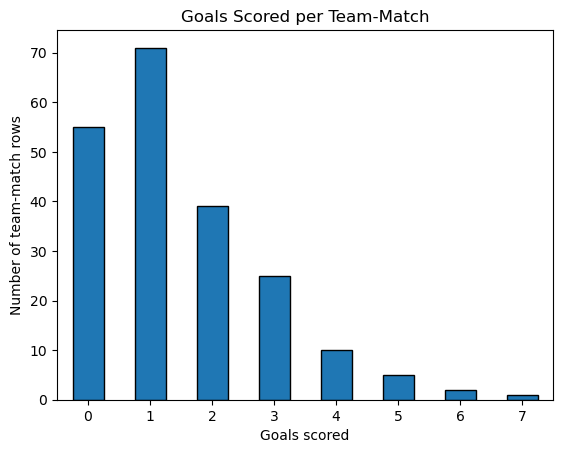

In [5]:
goal_counts = reg22_data["goals_scored"].value_counts().sort_index()

print("Goal-count summary:")
print(reg22_data["goals_scored"].describe())

print("\nNumber of team-match rows for each goal count:")
display(goal_counts.to_frame("team_match_rows"))

goal_counts.plot(kind="bar", edgecolor="black")
plt.title("Goals Scored per Team-Match")
plt.xlabel("Goals scored")
plt.ylabel("Number of team-match rows")
plt.xticks(rotation=0)
plt.show()

### Modelling Table

In [6]:
reg22_data = team_match_data[
    ["match_id", "Date", "team", "opponent"]
    + predictor_cols_22
    + ["goals_scored"]
].copy()

print(reg22_data.shape)
print(reg22_data.columns.tolist())

(208, 13)
['match_id', 'Date', 'team', 'opponent', 'team_fifa_rank', 'opponent_fifa_rank', 'team_prior_goals_for_avg', 'opponent_prior_goals_against_avg', 'is_home', 'team_rest_days', 'opponent_rest_days', 'days_since_tournament_start', 'goals_scored']


### Split training and test data by date

In [7]:
#count rows per date to stop split dividing a match between sets
rows_per_date = reg22_data.groupby("Date").size().sort_index()
target_train_rows = int(0.8 * len(reg22_data))
cumulative_rows = rows_per_date.cumsum()

train_end_date = (cumulative_rows - target_train_rows).abs().idxmin()

train_data = reg22_data[reg22_data["Date"] <= train_end_date].copy()
test_data = reg22_data[reg22_data["Date"] > train_end_date].copy()

X_train = train_data[predictor_cols_22]
y_train = train_data["goals_scored"]

X_test = test_data[predictor_cols_22]
y_test = test_data["goals_scored"]

print("Training rows:", len(train_data))
print("Test rows:", len(test_data))
print("Training matches:", train_data["match_id"].nunique())
print("Test matches:", test_data["match_id"].nunique())
print("Last training date:", train_end_date)
print(
    "Matches appearing in both sets:",
    len(set(train_data["match_id"]) & set(test_data["match_id"]))
)

Training rows: 164
Test rows: 44
Training matches: 82
Test matches: 22
Last training date: 2026-07-01 00:00:00
Matches appearing in both sets: 0


### linear regression and compare with baseline

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Fit the regression using the training data
model_22 = LinearRegression()
model_22.fit(X_train, y_train)

# Predict goals for the later test matches
y_pred = model_22.predict(X_test)

# Baseline: predict the training-set average for every test row
baseline_pred = [y_train.mean()] * len(y_test)

# Calculate model performance
model_mae = mean_absolute_error(y_test, y_pred)
model_rmse = mean_squared_error(y_test, y_pred) ** 0.5
model_r2 = r2_score(y_test, y_pred)

# Calculate baseline performance
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = mean_squared_error(y_test, baseline_pred) ** 0.5

print("Linear regression results")
print("MAE:", model_mae)
print("RMSE:", model_rmse)
print("R-squared:", model_r2)

print("\nMean-baseline results")
print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)

Linear regression results
MAE: 0.9833715656926039
RMSE: 1.326382485889501
R-squared: -0.005605670451981792

Mean-baseline results
Baseline MAE: 1.065410199556541
Baseline RMSE: 1.3237504732988465


### test-set prediction

In [9]:
results_22 = test_data.loc[
    X_test.index,
    ["match_id", "Date", "team", "opponent", "goals_scored"]
].copy()

results_22["predicted_goals"] = y_pred
results_22["residual"] = (
    results_22["goals_scored"] - results_22["predicted_goals"]
)

print("Lowest predicted goals:", results_22["predicted_goals"].min())
print("Highest predicted goals:", results_22["predicted_goals"].max())
print("Negative predictions:", (results_22["predicted_goals"] < 0).sum())

display(results_22.head(10).round(2))

Lowest predicted goals: -0.029980699955216572
Highest predicted goals: 2.8097175532404566
Negative predictions: 2


,match_id,Date,team,opponent,goals_scored,predicted_goals,residual
164,83,2026-07-02,Spain,Austria,3,2.42,0.58
165,83,2026-07-02,Austria,Spain,0,0.35,-0.35
166,84,2026-07-02,Portugal,Croatia,2,1.80,0.20
167,84,2026-07-02,Croatia,Portugal,1,1.05,-0.05
168,85,2026-07-02,Switzerland,Algeria,2,2.81,-0.81
169,85,2026-07-02,Algeria,Switzerland,0,-0.01,0.01
170,86,2026-07-03,Australia,Egypt,1,1.74,-0.74
171,86,2026-07-03,Egypt,Australia,1,0.64,0.36
172,87,2026-07-03,Argentina,Cabo Verde,3,2.29,0.71
173,87,2026-07-03,Cabo Verde,Argentina,2,0.16,1.84


### Check residuals

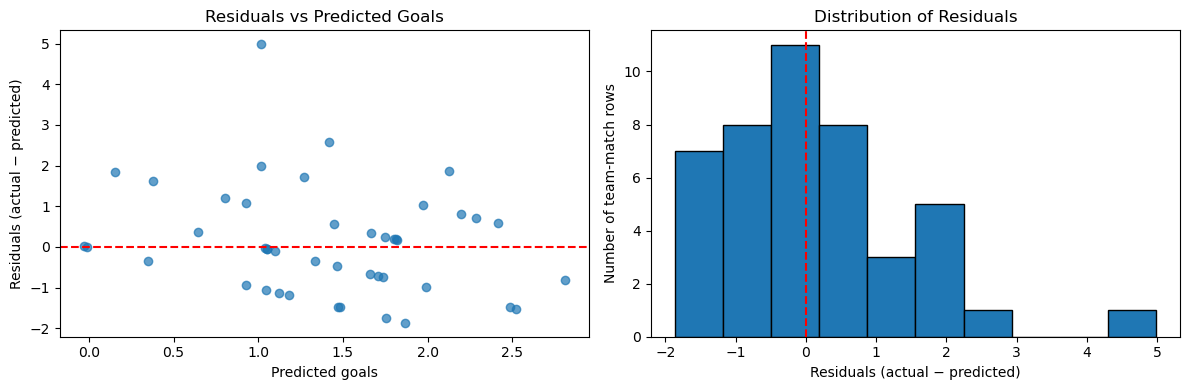

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Residuals against predicted goals
axes[0].scatter(
    results_22["predicted_goals"],
    results_22["residual"],
    alpha=0.7
)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Residuals vs Predicted Goals")
axes[0].set_xlabel("Predicted goals")
axes[0].set_ylabel("Residuals (actual − predicted)")

# Distribution of residuals
axes[1].hist(results_22["residual"], bins=10, edgecolor="black")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Distribution of Residuals")
axes[1].set_xlabel("Residuals (actual − predicted)")
axes[1].set_ylabel("Number of team-match rows")

plt.tight_layout()
plt.show()

### Inspect fitted coefficient

In [11]:
#each and every predictor name pairs with its coefficient 
coef_table_22 = pd.DataFrame({
    "predictor": predictor_cols_22,
    "coefficient": model_22.coef_
}).sort_values("coefficient")

print("Intercept:", model_22.intercept_)
display(coef_table_22.round(3))

Intercept: 1.4295567202311268


,predictor,coefficient
6,opponent_rest_days,-0.366
0,team_fifa_rank,-0.018
7,days_since_tournament_start,0.003
2,team_prior_goals_for_avg,0.012
1,opponent_fifa_rank,0.018
3,opponent_prior_goals_against_avg,0.146
5,team_rest_days,0.288
4,is_home,0.330


### Saving the outputs

In [12]:
reg22_data.to_csv("regression_2_2_team_match_dataset.csv", index=False)
results_22.to_csv("regression_2_2_test_predictions.csv", index=False)
coef_table_22.to_csv("regression_2_2_coefficients.csv", index=False)

print("Saved the 2.2 dataset, test predictions, and coefficient table.")

Saved the 2.2 dataset, test predictions, and coefficient table.


In [13]:
saved22 = pd.read_csv("regression_2_2_team_match_dataset.csv")

print("Shape:", saved22.shape)
print("Predictors:", len(predictor_cols_22))
print("Missing predictor values:",
      saved22[predictor_cols_22].isna().sum().sum())
print("Duplicate match-team rows:",
      saved22.duplicated(["match_id", "team"]).sum())

Shape: (208, 13)
Predictors: 8
Missing predictor values: 0
Duplicate match-team rows: 0
